# Creating controled synthetic phenotypes

## Import libraries

In [69]:
import pandas as pd
import numpy as np
import os
import math
import seaborn as sns
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import GofChisquarePower
from sklearn.cluster import KMeans
import sklearn.metrics as sil

## Load Humans

In [70]:
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)

In [71]:
dim = pd.read_pickle('./data/phenotype/reduction_of_ae_2_dims_5001_seconds.pkl')

In [72]:
humans = pd.concat([humans,dim.reindex(humans.index)], axis = 1)
humans

,sample,sample.1,pop,super_pop,gender,dim1,dim2
0,HG00096,HG00096,GBR,EUR,male,-0.676137,-1.771319
1,HG00097,HG00097,GBR,EUR,female,-0.653159,-1.784051
2,HG00099,HG00099,GBR,EUR,female,-0.566496,-1.689822
3,HG00100,HG00100,GBR,EUR,female,-0.745646,-1.872236
4,HG00101,HG00101,GBR,EUR,male,-0.588281,-1.689067
...,...,...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female,0.668300,-0.500961
2500,NA21141,NA21141,GIH,SAS,female,0.560910,-0.533208
2501,NA21142,NA21142,GIH,SAS,female,0.511824,-0.398424
2502,NA21143,NA21143,GIH,SAS,female,0.560548,-0.453115


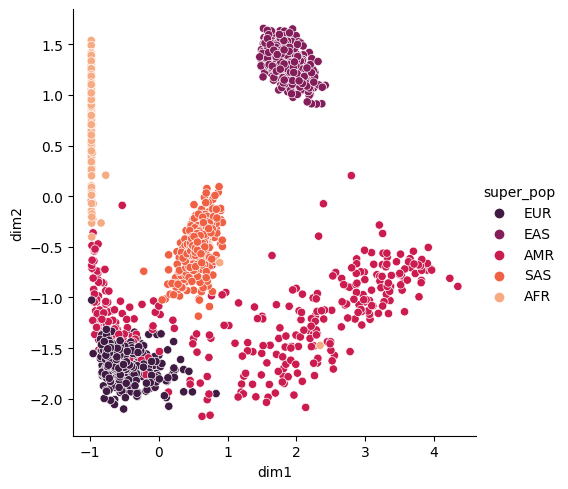

In [73]:
g = sns.relplot(
    data=humans,
    x="dim1", y="dim2",
    hue="super_pop",
    palette='rocket', sizes=(10, 200))
plt.show()

In [74]:
score = sil.silhouette_score(humans[[f"dim1",f"dim2"]], humans['pop'], metric='euclidean')
score

-0.089659765

# Load snps

In [75]:
os.listdir('./data/genotype')

['0_0_115_0_maf_0.01_0.01.pkl',
 '21_9_120_21_maf_0.024_0.025.pkl',
 '124_0_118_124_maf_0.4_0.41.pkl',
 '107_3_80_107_maf_0.3_0.31.pkl',
 '48_9_120_48_maf_0.068_0.07.pkl',
 '42_9_80_42_maf_0.055_0.057.pkl',
 '39_9_103_39_maf_0.05_0.051.pkl',
 '87_0_110_87_maf_0.2_0.2.pkl',
 '26_9_120_26_maf_0.03_0.031.pkl',
 '16_9_92_16_maf_0.02_0.021.pkl',
 '33_9_89_33_maf_0.04_0.041.pkl',
 '57_7_120_57_maf_0.091_0.094.pkl',
 '44_9_114_44_maf_0.059_0.061.pkl',
 '36_9_80_36_maf_0.044_0.046.pkl',
 '53_1_116_53_maf_0.08_0.083.pkl',
 '138_9_80_138_maf_0.49_0.49.pkl',
 '75_4_91_75_maf_0.15_0.15.pkl',
 '30_9_80_30_maf_0.035_0.037.pkl',
 '60_2_120_60_maf_0.1_0.1.pkl',
 '8_9_120_8_maf_0.014_0.015.pkl',
 '97_4_80_97_maf_0.25_0.25.pkl']

In [76]:
min_maf = 0.03
max_maf = 0.04

In [77]:
snps = [f for f in os.listdir('./data/genotype') if  max_maf > float(f.split("_maf_")[1].split('.pkl')[0].split('_')[0]) > min_maf]
snps

['30_9_80_30_maf_0.035_0.037.pkl']

In [78]:
snp_num = 0
for snp in snps[0:1]:
    maf = snp.split("_maf_")[1].split('.pkl')[0]
    print(maf)
    path_snp = f"./data/genotype/{snp}"
    print(path_snp)
    geno = pd.read_pickle(path_snp)
    
    geno[geno.columns[snp_num]].value_counts()
    num_maj = geno[geno.columns[snp_num]].value_counts()[1]
    num_het = geno[geno.columns[snp_num]].value_counts()[0]
    try:
        num_min = geno[geno.columns[snp_num]].value_counts()[-1]
    except Exception as e:
        num_min = 0
    total_humans = num_maj + num_het + num_min
    maf = (num_min*2 + num_het)/(total_humans*2)
    humans[str(round(maf,3))] = geno[geno.columns[snp_num]]

0.035_0.037
./data/genotype/30_9_80_30_maf_0.035_0.037.pkl


In [79]:
humans

,sample,sample.1,pop,super_pop,gender,dim1,dim2,0.037
0,HG00096,HG00096,GBR,EUR,male,-0.676137,-1.771319,1
1,HG00097,HG00097,GBR,EUR,female,-0.653159,-1.784051,1
2,HG00099,HG00099,GBR,EUR,female,-0.566496,-1.689822,1
3,HG00100,HG00100,GBR,EUR,female,-0.745646,-1.872236,1
4,HG00101,HG00101,GBR,EUR,male,-0.588281,-1.689067,1
...,...,...,...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female,0.668300,-0.500961,1
2500,NA21141,NA21141,GIH,SAS,female,0.560910,-0.533208,1
2501,NA21142,NA21142,GIH,SAS,female,0.511824,-0.398424,1
2502,NA21143,NA21143,GIH,SAS,female,0.560548,-0.453115,1


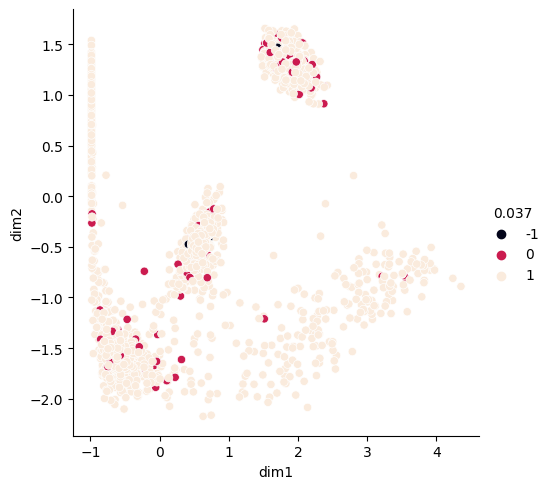

In [80]:
g = sns.relplot(
    data=humans,
    x="dim1", y="dim2",
    hue="0.037",
    palette='rocket', sizes=(10, 200))
plt.show()

## Scenario 1: AF + popstrat dependent phenotype (LD snps)

In [81]:
max_maf = 0.6
min_maf = 0.3

In [82]:
dims = [f for f in os.listdir('./data/phenotype/unshuffled_reduced') if  max_maf > float(f.split("_maf_")[1].split('.pkl')[0].split('_')[0]) > min_maf]
dims

['22_0_1200_22_maf_0.37_0.43.pkl',
 '22_9_1200_22_maf_0.37_0.43.pkl',
 '21_4_800_21_maf_0.31_0.37.pkl',
 '21_1_1200_21_maf_0.31_0.37.pkl',
 '21_6_1200_21_maf_0.31_0.37.pkl',
 '21_9_1017_21_maf_0.31_0.37.pkl',
 '21_3_891_21_maf_0.31_0.37.pkl',
 '23_2_800_23_maf_0.43_0.49.pkl',
 '23_9_1041_23_maf_0.43_0.49.pkl',
 '23_3_1200_23_maf_0.43_0.49.pkl',
 '22_7_1200_22_maf_0.37_0.43.pkl',
 '22_1_996_22_maf_0.37_0.43.pkl',
 '23_4_959_23_maf_0.43_0.49.pkl',
 '23_0_1200_23_maf_0.43_0.49.pkl',
 '23_8_1200_23_maf_0.43_0.49.pkl',
 '22_6_800_22_maf_0.37_0.43.pkl',
 '21_7_800_21_maf_0.31_0.37.pkl',
 '21_5_892_21_maf_0.31_0.37.pkl',
 '22_5_800_22_maf_0.37_0.43.pkl',
 '22_8_809_22_maf_0.37_0.43.pkl',
 '21_2_800_21_maf_0.31_0.37.pkl',
 '22_4_995_22_maf_0.37_0.43.pkl',
 '23_6_800_23_maf_0.43_0.49.pkl',
 '21_8_1200_21_maf_0.31_0.37.pkl',
 '21_0_1200_21_maf_0.31_0.37.pkl',
 '23_5_800_23_maf_0.43_0.49.pkl',
 '22_2_800_22_maf_0.37_0.43.pkl',
 '23_7_800_23_maf_0.43_0.49.pkl',
 '22_3_1200_22_maf_0.37_0.43.pkl',
 

In [83]:
snp_num = 0
for dim in dims[1:2]:
    maf = dim.split("_maf_")[1].split('.pkl')[0].split("_")[0]
    print(maf)
    path_snp = f"./data/phenotype/unshuffled_reduced/{dim}"
    print(path_snp)
    mini_dim = pd.read_pickle(path_snp)


0.37
./data/phenotype/unshuffled_reduced/22_9_1200_22_maf_0.37_0.43.pkl


In [84]:
humans[f"maf_{maf}_dim1"] = mini_dim['dim1']
humans[f"maf_{maf}_dim2"] = mini_dim['dim2']

In [85]:
humans

,sample,sample.1,pop,super_pop,gender,dim1,dim2,0.037,maf_0.37_dim1,maf_0.37_dim2
0,HG00096,HG00096,GBR,EUR,male,-0.676137,-1.771319,1,-0.043317,1.015291
1,HG00097,HG00097,GBR,EUR,female,-0.653159,-1.784051,1,-0.193059,0.241459
2,HG00099,HG00099,GBR,EUR,female,-0.566496,-1.689822,1,-0.465019,-0.228906
3,HG00100,HG00100,GBR,EUR,female,-0.745646,-1.872236,1,-1.331270,0.576430
4,HG00101,HG00101,GBR,EUR,male,-0.588281,-1.689067,1,-0.442783,-0.101128
...,...,...,...,...,...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female,0.668300,-0.500961,1,0.528698,0.908940
2500,NA21141,NA21141,GIH,SAS,female,0.560910,-0.533208,1,0.026765,-0.334037
2501,NA21142,NA21142,GIH,SAS,female,0.511824,-0.398424,1,0.344574,1.124886
2502,NA21143,NA21143,GIH,SAS,female,0.560548,-0.453115,1,0.649083,-0.539392


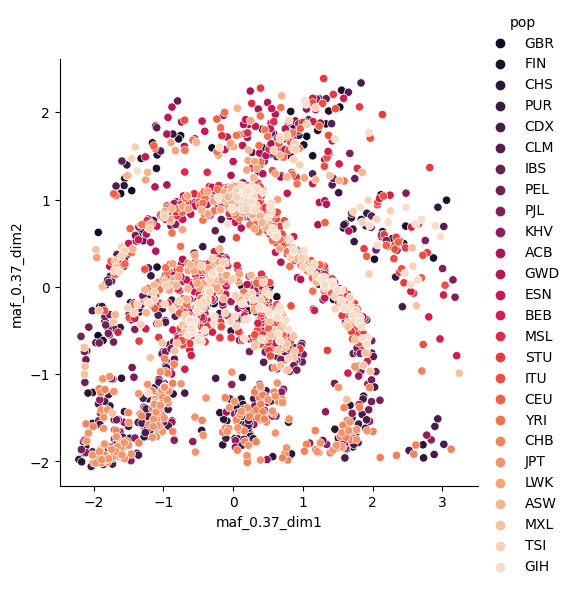

In [86]:
g = sns.relplot(
    data=humans,
    x=f"maf_{maf}_dim1", y=f"maf_{maf}_dim2",
    hue="pop",
    palette='rocket', sizes=(10, 200))
plt.show()

In [87]:
print(np.random.seed(10))

None


In [88]:
# create 3 samples of random dots
dif = 5
ratio = 0.4
mean = 0
mean1 = mean - dif
mean2 = mean
mean3 = mean + dif
sigma = dif * ratio
s11 = np.random.normal(mean1, sigma, 1000)
s12 = np.random.normal(mean1, sigma, 1000)
label1 = ['label 1'] * len(s11)

s21 = np.random.normal(mean2, sigma, 1000)
s22 = np.random.normal(mean2, sigma, 1000)
label2 = ['label 2'] * len(s21)

s31 = np.random.normal(mean3, sigma, 1000)
s32 = np.random.normal(mean3, sigma, 1000)
label3 = ['label 3'] * len(s31)

In [89]:
df = pd.DataFrame({"dim1":np.concatenate((s11, s21, s31)), "dim2": np.concatenate((s12, s22, s32)), 'label': label1 + label2 + label3})

In [90]:
df

,dim1,dim2,label
0,-2.336827,-1.973496,label 1
1,-3.569442,-5.284667,label 1
2,-8.090801,-5.278840,label 1
3,-5.016768,-2.648985,label 1
4,-3.757328,-2.632422,label 1
...,...,...,...
2995,7.307043,2.510674,label 3
2996,3.561907,4.741287,label 3
2997,2.114892,3.025105,label 3
2998,5.776780,6.280319,label 3


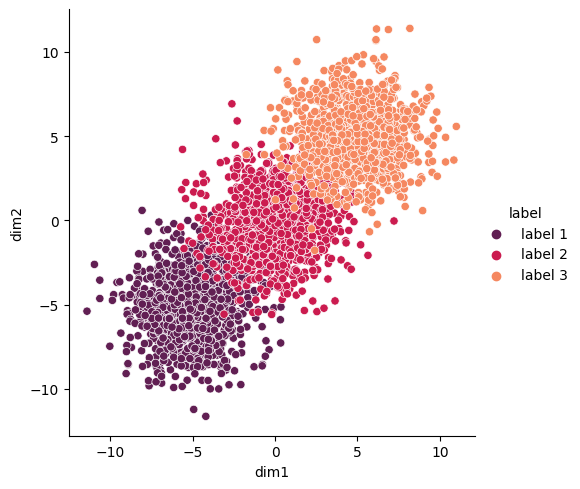

In [91]:
g = sns.relplot(
    data=df,
    x=f"dim1", y=f"dim2",
    hue="label",
    palette='rocket', sizes=(10, 200))
plt.show()

In [92]:
km = KMeans(n_clusters=3, random_state=42)
km.fit_predict(df[['dim1','dim2']])

array([0, 1, 1, ..., 2, 2, 2], dtype=int32)

In [93]:
score = sil.silhouette_score(df[['dim1','dim2']], km.labels_, metric='euclidean')
score

0.5035900985976353

In [94]:
score = sil.silhouette_score(df[['dim1','dim2']], df['label'], metric='euclidean')

In [95]:
score

0.47304216661557835

In [96]:
df['pred_label'] = km.labels_

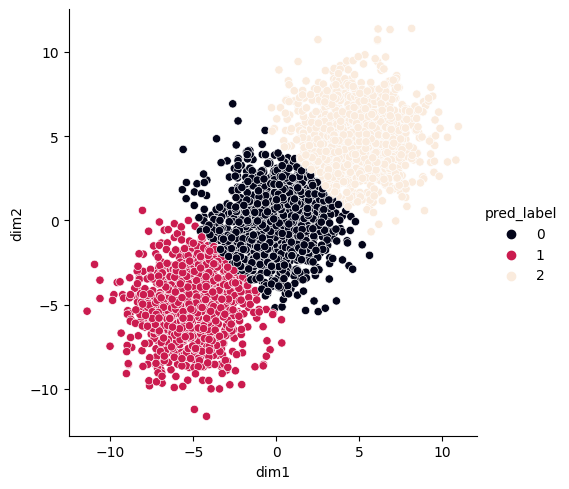

In [97]:
g = sns.relplot(
    data=df,
    x=f"dim1", y=f"dim2",
    hue="pred_label",
    palette='rocket', sizes=(10, 200))
plt.show()

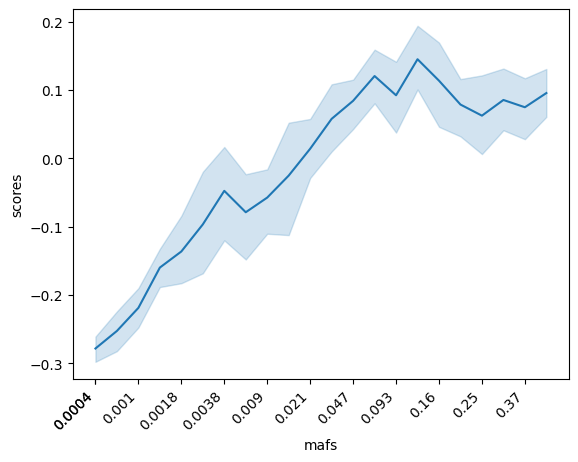

In [98]:
sil_scores = []
mafs = []
dims = [f for f in os.listdir('./data/phenotype/unshuffled_reduced')]
dimsy = dims[0:-1]
for o in range(len(dimsy)):
    maf = dimsy[o].split("_maf_")[1].split('.pkl')[0].split("_")[0]
    path_dim = f"./data/phenotype/unshuffled_reduced/{dimsy[o]}"
    mini_dim = pd.read_pickle(path_dim)
    humans[f"{o}_maf_{maf}_dim1"] = mini_dim['dim1']
    humans[f"{o}_maf_{maf}_dim2"] = mini_dim['dim2']
    score = sil.silhouette_score(humans[[f"{o}_maf_{maf}_dim1",f"{o}_maf_{maf}_dim2"]], humans['super_pop'], metric='euclidean')
    sil_scores.append(score)
    mafs.append(maf)

df = pd.DataFrame(data = {'scores':sil_scores, 'mafs':mafs})
df = df.sort_values(by=['mafs'], ignore_index=True)
sns.lineplot(data=df, x="mafs", y="scores")
plt.xticks(
    df['mafs'].iloc[::20], # Odd rows only
    rotation=45,
    horizontalalignment='right'
)
plt.show()

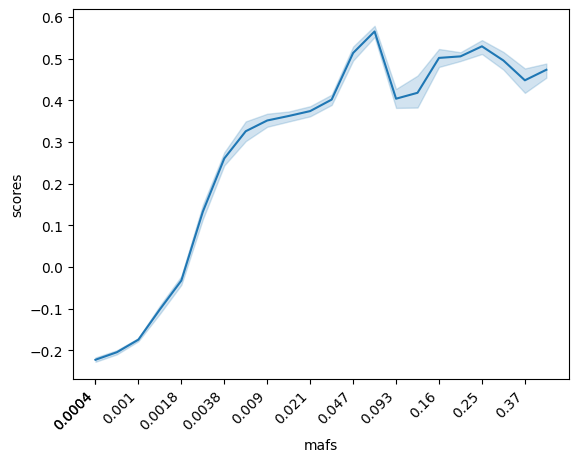

In [99]:
sil_scores = []
mafs = []
dims = [f for f in os.listdir('./data/phenotype/shuffled_reduced')]
dimsy = dims[0:-1]
for o in range(len(dimsy)):
    maf = dimsy[o].split("_maf_")[1].split('.pkl')[0].split("_")[0]
    path_dim = f"./data/phenotype/shuffled_reduced/{dimsy[o]}"
    mini_dim = pd.read_pickle(path_dim)
    humans[f"{o}_maf_{maf}_dim1"] = mini_dim['dim1']
    humans[f"{o}_maf_{maf}_dim2"] = mini_dim['dim2']
    score = sil.silhouette_score(humans[[f"{o}_maf_{maf}_dim1",f"{o}_maf_{maf}_dim2"]], humans['super_pop'], metric='euclidean')
    sil_scores.append(score)
    mafs.append(maf)

df = pd.DataFrame(data = {'scores':sil_scores, 'mafs':mafs})
df = df.sort_values(by=['mafs'], ignore_index=True)
sns.lineplot(data=df, x="mafs", y="scores")
plt.xticks(
    df['mafs'].iloc[::20], # Odd rows only
    rotation=45,
    horizontalalignment='right'
)
plt.show()

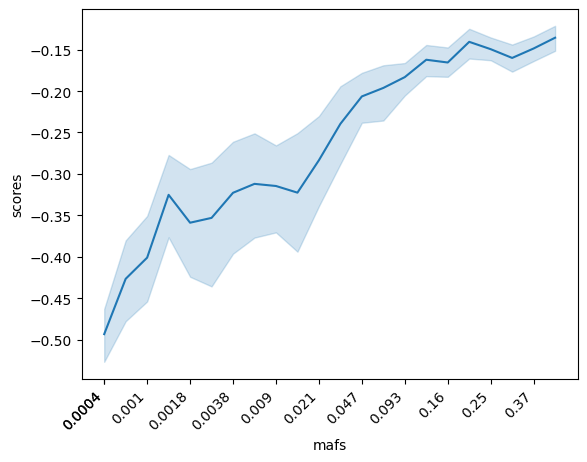

In [100]:
sil_scores = []
mafs = []
dims = [f for f in os.listdir('./data/phenotype/unshuffled_reduced')]
dimsy = dims[0:-1]
for o in range(len(dimsy)):
    maf = dimsy[o].split("_maf_")[1].split('.pkl')[0].split("_")[0]
    path_dim = f"./data/phenotype/unshuffled_reduced/{dimsy[o]}"
    mini_dim = pd.read_pickle(path_dim)
    humans[f"{o}_maf_{maf}_dim1"] = mini_dim['dim1']
    humans[f"{o}_maf_{maf}_dim2"] = mini_dim['dim2']
    score = sil.silhouette_score(humans[[f"{o}_maf_{maf}_dim1",f"{o}_maf_{maf}_dim2"]], humans['pop'], metric='euclidean')
    sil_scores.append(score)
    mafs.append(maf)

df = pd.DataFrame(data = {'scores':sil_scores, 'mafs':mafs})
df = df.sort_values(by=['mafs'], ignore_index=True)
sns.lineplot(data=df, x="mafs", y="scores")
plt.xticks(
    df['mafs'].iloc[::20], # Odd rows only
    rotation=45,
    horizontalalignment='right'
)
plt.show()

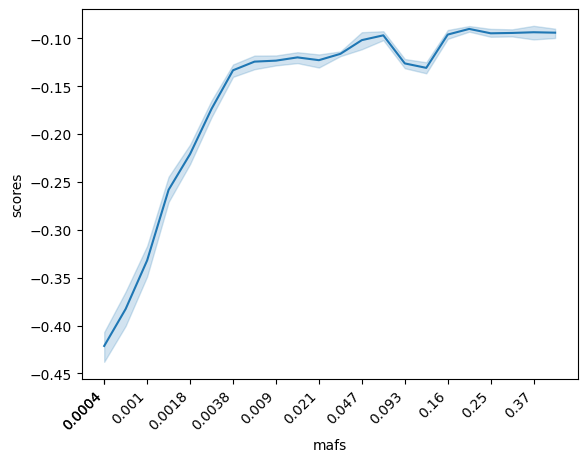

In [101]:
sil_scores = []
mafs = []
dims = [f for f in os.listdir('./data/phenotype/shuffled_reduced')]
dimsy = dims[0:-1]
for o in range(len(dimsy)):
    maf = dimsy[o].split("_maf_")[1].split('.pkl')[0].split("_")[0]
    path_dim = f"./data/phenotype/shuffled_reduced/{dimsy[o]}"
    mini_dim = pd.read_pickle(path_dim)
    humans[f"{o}_maf_{maf}_dim1"] = mini_dim['dim1']
    humans[f"{o}_maf_{maf}_dim2"] = mini_dim['dim2']
    score = sil.silhouette_score(humans[[f"{o}_maf_{maf}_dim1",f"{o}_maf_{maf}_dim2"]], humans['pop'], metric='euclidean')
    sil_scores.append(score)
    mafs.append(maf)

df = pd.DataFrame(data = {'scores':sil_scores, 'mafs':mafs})
df = df.sort_values(by=['mafs'], ignore_index=True)
sns.lineplot(data=df, x="mafs", y="scores")
plt.xticks(
    df['mafs'].iloc[::20], # Odd rows only
    rotation=45,
    horizontalalignment='right'
)
plt.show()